In [1]:
import numpy as np
import pandas as pd
import json

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.utils  import resample

# import config
from pathlib import Path

import shap

c:\Miniforge-Data\envs\Data_Analysis\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Functions and description
This analysis prepares the data and makes an analysis with a surrogate approach and boostrapping. 


In [2]:
def load_jdata(jsonl_file):
    with open(jsonl_file, 'r') as f:
        data = [json.loads(line) for line in f]
    return data

def get_metric_array(data, metric_key):
    data.sort(key=lambda x: x['index'])
    return np.array([item[metric_key] for item in data])

# def quality_check(X:pd.DataFrame,y:pd.Series,n_estimators:int=100,random_state:int=100) -> None:
#     surrogate_check = RandomForestRegressor(n_estimators=100, random_state=100)
#     surrogate_check.fit(X,y)

#     y_pred = surrogate_check.predict(X)
#     r2=r2_score(y,y_pred)
#     rmse= np.sqrt(mean_squared_error(y,y_pred))

#     print("check results")
#     print(f'R^2 score:  {r2:.4f}')
#     print(f'RMSE:       {rmse:.4e}')

#     if r2<0.80:
#         print('Warning: Low R^2 score. Alternatives: increasing tree depth, gradient boosting, or log-transforming y.')#if not applied
#     else:
#         print("Surrogate accurately mirrors OGS-DFN response surface")


def interpolator_fitting(
    x_array: np.ndarray,
    y: np.ndarray,
    variable_name: list[str] | str= 'y',
    n_splits: int = 5
) -> plt.Figure:

    from sklearn.model_selection import KFold
    from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)
    
    oof_predictions = np.zeros_like(y)
    fold_rmses = []
    
    # K-Fold loop to test true interpolation error on unseen folds
    for train_idx, test_idx in kf.split(x_array):
        X_tr, y_tr = x_array[train_idx], y[train_idx]
        X_te, y_te = x_array[test_idx], y[test_idx]

        k_fold = RandomForestRegressor(n_estimators=50, random_state=42)
        k_fold.fit(X_tr, y_tr)
        preds = k_fold.predict(X_te)
        
        oof_predictions[test_idx] = preds
        fold_rmses.append(np.sqrt(mean_squared_error(y_te, preds)))

    # Compute Out-of-Fold overall metrics
    r2_oof = r2_score(y, oof_predictions)
    mae_oof = mean_absolute_error(y, oof_predictions)
    rmse_oof = np.sqrt(mean_squared_error(y, oof_predictions))

    print(f"=== {n_splits}-Fold Cross-Validation Diagnostics ===")
    print(f"Mean Fold {variable_name}:            {np.mean(fold_rmses):.6f} (± {np.std(fold_rmses):.6f})")
    print(f"Overall OOF R² Score:      {r2_oof:.4f}")
    print(f"Overall OOF MAE:           {mae_oof:.6f}")
    print(f"Overall OOF {variable_name}:          {rmse_oof:.6f}")

    fig, ax = plt.subplots(figsize=(6, 6))

    ax.scatter(y, oof_predictions, alpha=0.6, color='teal', edgecolor='k', label='Out-of-Fold Test Points')
    ax.plot(
        [y.min(), y.max()], 
        [y.min(), y.max()], 
        'r--', label='1:1 Perfect Fit'
    )

    ax.set_xlabel(f'Observed Min {variable_name} [Pa]')
    ax.set_ylabel(f'Cross-Validated Interpolated {variable_name} [Pa]')
    ax.set_title(f'K-Fold Cross-Validation Accuracy (R² = {r2_oof:.3f})')
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend()
    fig.tight_layout()
    plt.close(fig)
    return fig

def analyse_si_convergence(X:pd.DataFrame,y:pd.Series,sample_steps:np.array=None,n_bootstraps=30)->dict:
    "SI with evolving n runs simulations "

    N_total=len(X)
    if sample_steps is None:
        sample_steps=np.linspace(30,N_total,num=10,dtype=int)

    features= X.columns.tolist()

    convergence_data={f:{'mean':[],'lower':[],'upper':[]} for f in features}
    rng = np.random.default_rng(42)

    for n_sub in sample_steps:
        boot_si=[]

        for b in range(n_bootstraps):

            idx= rng.choice(N_total,size=n_sub,replace=False)
            X_sub, y_sub = X.iloc[idx],y.iloc[idx]

            model= RandomForestRegressor(
                n_estimators=50,
                max_depth=6, #contorls overfitting
                random_state=b,
                n_jobs=-1
            )
            model.fit(X_sub,y_sub)

            explainer=shap.TreeExplainer(model) 
            shap_vals=explainer.shap_values(X_sub) #shape values

            if isinstance(shap_vals, list):
                shap_vals = shap_vals[0]

            global_si=np.mean(np.abs(shap_vals),axis=0) 
            boot_si.append(global_si)

        boot_si=np.array(boot_si) 

        #stats for each feature at size n_sub
        for i, f in enumerate(features):
            convergence_data[f]['mean'].append(np.mean(boot_si[:,i]))
            convergence_data[f]['lower'].append(np.percentile(boot_si[:,i],2.5))
            convergence_data[f]['upper'].append(np.percentile(boot_si[:,i],97.5))
    
    return convergence_data

def graph_shap_c(results:dict,sample_steps:np.array,phase:str,ci:bool,grid:bool,size:tuple):

    SI_conv=results[phase].copy()
    features= list(SI_conv.keys())

    fig, axs= plt.subplots(figsize=(size))

    markers = ['o', 's', '^', 'D', 'v', 'X', 'p', '*']
    colors=['tab:blue','tab:orange','tab:green','tab:red','tab:purple','tab:brown','tab:pink','tab:gray']

    for i,  f in enumerate(features):
        if ci:
            current_marker = markers[i % len(markers)]
            current_color= colors[i % len(colors)]
            means=SI_conv[f]['mean']
            lower=SI_conv[f]['lower']
            upper=SI_conv[f]['upper']
            axs.plot(sample_steps,means,label=f,marker=current_marker,color=current_color, linewidth=2)[0]
            axs.plot(sample_steps,lower,ls='--',color=current_color, linewidth=1)[0]
            axs.plot(sample_steps,upper,ls='--',color=current_color, linewidth=1)[0]

        else:
            current_marker = markers[i % len(markers)]
            current_color= colors[i % len(colors)]
            means=SI_conv[f]['mean']
            axs.plot(sample_steps,means,label=f,marker=current_marker,color=current_color, linewidth=2)[0]

    plt.title(f"SHAP - SA ({phase})")
    axs.set_xlabel("Number of runs: n= N(k+1)")
    axs.set_ylabel(r"$\mu^*$  Pa")
    plt.legend()
    if grid==True: plt.grid(True, linestyle='--', alpha=0.5)
    else: None
    plt.close(fig)
    return fig 

def convert_results_dict_to_df(results:dict,sample_steps:np.array)->pd.DataFrame:
    rows=[]

    for phase, params_dict in results.items():
        param_names= list(params_dict.keys())
        stat_keys= list(params_dict[param_names[0]].keys())

        for stat in stat_keys:

            for idx, step_val in enumerate(sample_steps):
                row={
                    'phase':phase,
                    'stat':stat,
                    'sub_n':idx+1,
                    'sample_steps':int(step_val) if hasattr(step_val, 'item') else step_val
                }

                for param in param_names:
                    row[param]=params_dict[param][stat][idx]

                rows.append(row)
                
    return pd.DataFrame(rows)

In [3]:
from sklearn.preprocessing import PowerTransformer

def power_transf(values: np.array):
    pt = PowerTransformer(method='yeo-johnson') # or 'box-cox'
    transformed_data = pt.fit_transform(values.reshape(-1, 1)) 
    print(f"best exponent: {pt.lambdas_}")

    return transformed_data

In [4]:
#loading and preparing the data
cwd = Path.cwd()
version_list=['v16']
results=[]
n_r=[] #runs per N parameter
for version in version_list:

    json_file= Path(f'{cwd}/results_{version}/results/results_archive_{version}.jsonl').resolve()
    sample_archive= Path(f'{cwd}/results_{version}/morris_samples_{version}.csv').resolve()

    df_X= pd.read_csv(sample_archive)
    df_Y = pd.DataFrame(load_jdata(json_file))



X=df_X.copy()
SI_names=df_Y.columns[1:]

for index in SI_names:
    df_Y[index]=power_transf(df_Y[index].values) #power transform

y_tot=[]
for index in SI_names:
    y=df_Y[index]
    y_tot.append(y)
feature_names = X.columns.to_list()
n_samples, n_features = X.shape

best exponent: [-0.50523879]
best exponent: [-0.4096654]
best exponent: [-0.54277072]


In [5]:
SI_names

Index(['sum_c', 'peak', 'p_end'], dtype='str')

# Analysis

In [6]:
#quality check

# for index in SI_names:
#     print(f'for Sensitivity Index: {index}')
#     quality_check(X,df_Y[index])
fig0=[]
for index in SI_names:
    tempfig=interpolator_fitting(X.values,df_Y[index].values,index)
    fig0.append(tempfig)


=== 5-Fold Cross-Validation Diagnostics ===
Mean Fold sum_c:            0.728083 (± 0.069717)
Overall OOF R² Score:      0.4650
Overall OOF MAE:           0.540250
Overall OOF sum_c:          0.731413
=== 5-Fold Cross-Validation Diagnostics ===
Mean Fold peak:            0.714182 (± 0.075946)
Overall OOF R² Score:      0.4842
Overall OOF MAE:           0.537735
Overall OOF peak:          0.718209
=== 5-Fold Cross-Validation Diagnostics ===
Mean Fold p_end:            0.867453 (± 0.046746)
Overall OOF R² Score:      0.2453
Overall OOF MAE:           0.658969
Overall OOF p_end:          0.868711


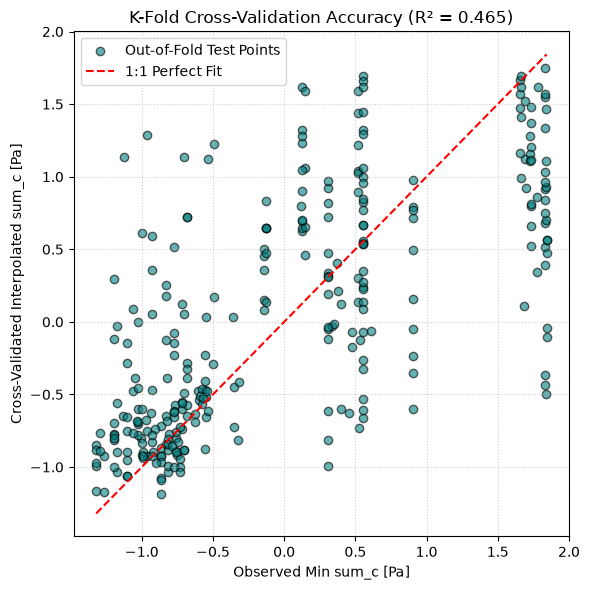

In [7]:
fig0[0]

In [8]:
#Running subsampling boostrapping
sample_steps=np.unique( np.concat([np.linspace(30,100,num=10,dtype=int),np.linspace(100,len(X),num=10,dtype=int)]))


In [9]:
#subsampling bootstrapping loop

results={}
for idx,name in enumerate(SI_names):
    SI_conv=analyse_si_convergence(X,y_tot[idx],sample_steps)
    results[name]=SI_conv


In [10]:
#saving registry in json (original shape) and csv tabular, including steps 

# com_results=results.copy()
# com_results['sample_steps']=sample_steps


# df=convert_results_dict_to_df(results,sample_steps)
# df.to_csv('sensitivity_results_v1.csv',index=False)

# com_results['sample_steps']=sample_steps.tolist() #to avoid conflicts of format
# with open('sensitivity_results_v1.json', 'w') as f:
#     json.dump(com_results,f,indent=2)

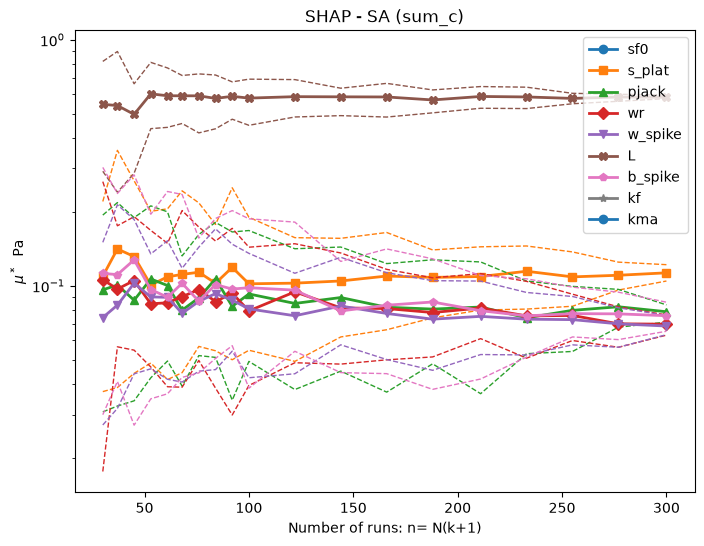

In [21]:
#production ready plot
phase='sum_c' #SI options: 'sum_c', 'peak', 'p_end'
conf_int=True
size=(8,6)
grid=True

fig1=graph_shap_c(results, sample_steps,phase,True,False,(8,6))
ax = fig1.axes[0] 
ax.set_yscale('log')
fig1

#dy naming
# namecomb1={'sum_c':1,
#            'peak':2,
#            'p_end':3,
#            }
# fig1.savefig(f'SHAP_SA_BH10_40_6_{namecomb1[phase]}.pdf',
#               format="pdf",
#             bbox_inches='tight',
#             pad_inches=0.05
#             ) 

# More graph analysis

In [12]:
# bootstrapping and SHAP sensitivity N total. PER Sensitivity Index Choosen
#Sensitivity Index only graph of global couple non-linearities is set -
sindex='sum_c'
y = df_Y[sindex]
n_bootstraps= 50 # standard 50 to 100
bootstrapped_importances=[]

print(f'Bootstrapping {n_bootstraps} level iterations')

for b in range(n_bootstraps):
    X_res, y_res = resample(X,y, random_state=b)

    model= RandomForestRegressor(
        n_estimators=100,
        max_depth=8, #contorls overfitting
        random_state=b,
        n_jobs=1
    )
    model.fit(X_res,y_res)

    explainer=shap.TreeExplainer(model) #shape values
    shap_vals=explainer.shap_values(X)

    global_si=np.mean(np.abs(shap_vals),axis=0) 
    bootstrapped_importances.append(global_si)

bootstrapped_importances= np.array(bootstrapped_importances)

mean_si = np.mean(bootstrapped_importances,axis=0)
ci_lower= np.percentile(bootstrapped_importances,2.5,axis=0)
ci_upper= np.percentile(bootstrapped_importances, 97.5,axis=0)

results_df= pd.DataFrame({
    'Parameter':feature_names,
    'Mean_Sensitivity':mean_si,
    'CI_2.5%':ci_lower,
    'CI_97.5%':ci_upper
}).sort_values(by='Mean_Sensitivity',ascending=False).reset_index(drop=True)

print("Sensitivity Analysis Result")
print(results_df.to_string(index=False))

Bootstrapping 50 level iterations
Sensitivity Analysis Result
Parameter  Mean_Sensitivity  CI_2.5%  CI_97.5%
        L          0.580382 0.524921  0.656137
   s_plat          0.127973 0.083515  0.180998
  b_spike          0.098192 0.059868  0.155764
    pjack          0.098025 0.065823  0.145062
       wr          0.096171 0.061523  0.140153
  w_spike          0.091669 0.055367  0.135897
      sf0          0.000000 0.000000  0.000000
       kf          0.000000 0.000000  0.000000
      kma          0.000000 0.000000  0.000000


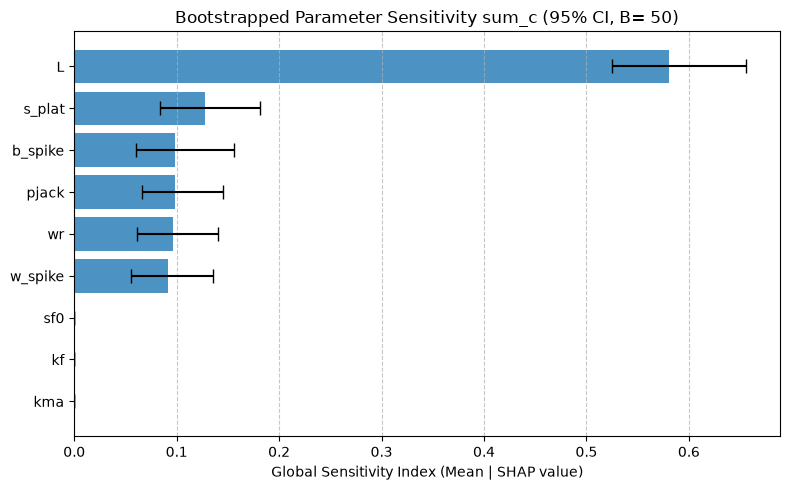

In [13]:
#visualization
plt.figure(figsize=(8,5))
y_pos=np.arange(len(results_df))

plt.barh(
    y_pos,
    results_df['Mean_Sensitivity'],
    xerr=[
        results_df['Mean_Sensitivity']-results_df['CI_2.5%'],
        results_df['CI_97.5%']-results_df['Mean_Sensitivity']
    ],
    align='center',
    alpha=0.8,
    ecolor='black',
    capsize=5
)

plt.yticks(y_pos,results_df['Parameter'])
plt.gca().invert_yaxis()
plt.xlabel('Global Sensitivity Index (Mean | SHAP value)')
plt.title(f'Bootstrapped Parameter Sensitivity {sindex} (95% CI, B= {n_bootstraps})')
plt.grid(axis='x', linestyle= '--', alpha=0.7)
plt.tight_layout()
plt.show()

## All N different analysis (no bootstrapping)

 SHAP Dependence sum_c: L


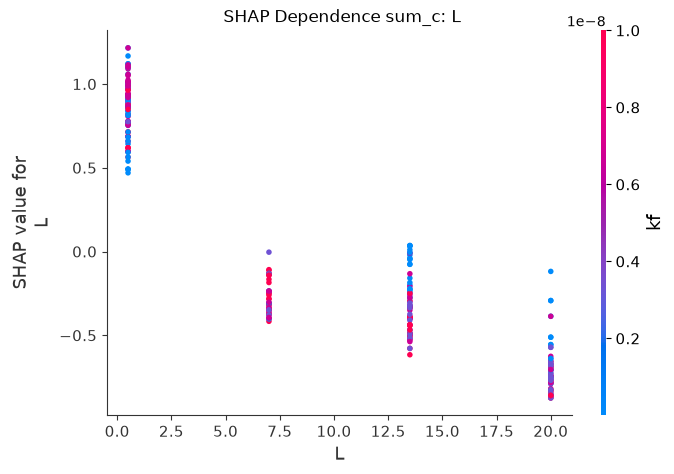

In [14]:
#non-linearity dependence
final_model= RandomForestRegressor(n_estimators=100,random_state=42).fit(X,y) #using full model (not bootstrapping)
final_explainer=shap.TreeExplainer(final_model)
final_shap_values= final_explainer(X)

top_param=results_df.iloc[0]['Parameter']
print(f' SHAP Dependence {sindex}: {top_param}')

fig3=shap.dependence_plot(top_param,final_shap_values.values,X,show = False)
plt.title(f' SHAP Dependence {sindex}: {top_param}')
fig3

 
#manual choosing secondary parameter
# secondary_param='sf3_log'
# fig3=shap.dependence_plot(top_param,
#                       final_shap_values.values,
#                      X,
#                       interaction_index=secondary_param,
#                         show=False)
# plt.title(f' SHAP Dependence {sindex}: {top_param}')

<Figure size 700x500 with 0 Axes>

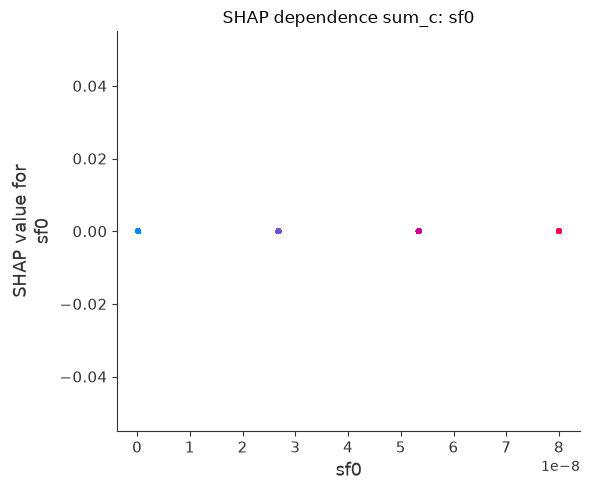

<Figure size 700x500 with 0 Axes>

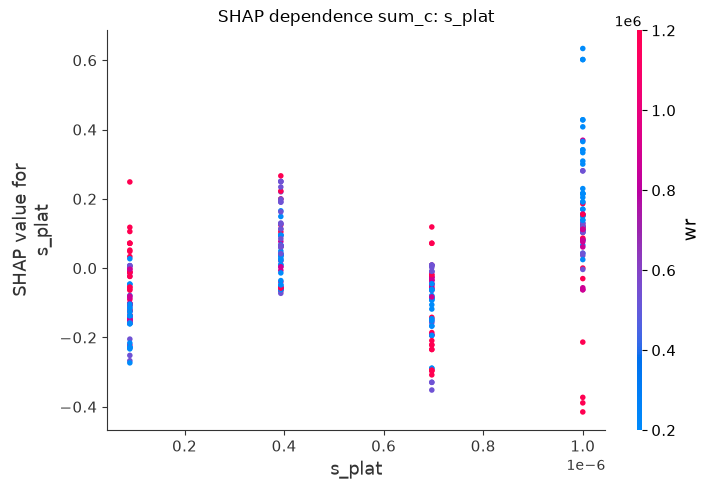

<Figure size 700x500 with 0 Axes>

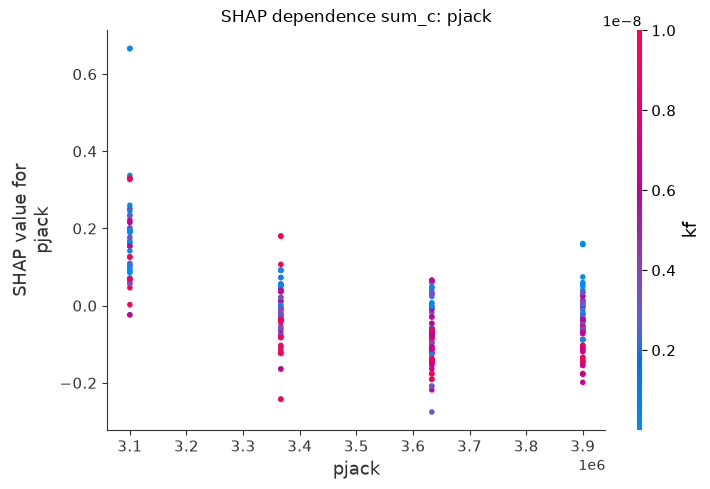

<Figure size 700x500 with 0 Axes>

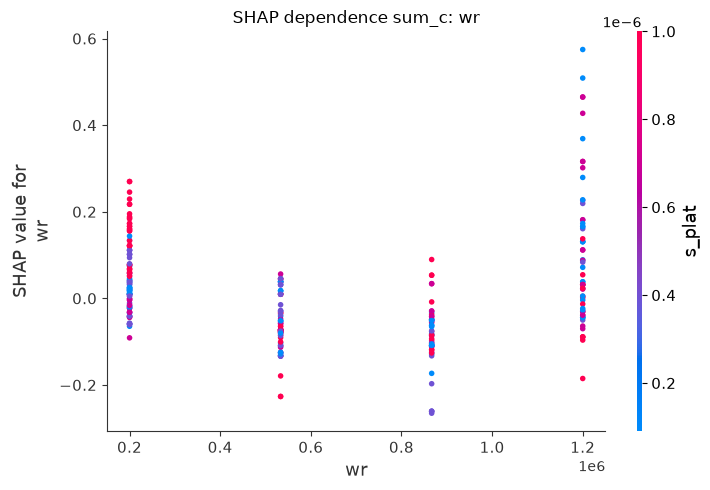

<Figure size 700x500 with 0 Axes>

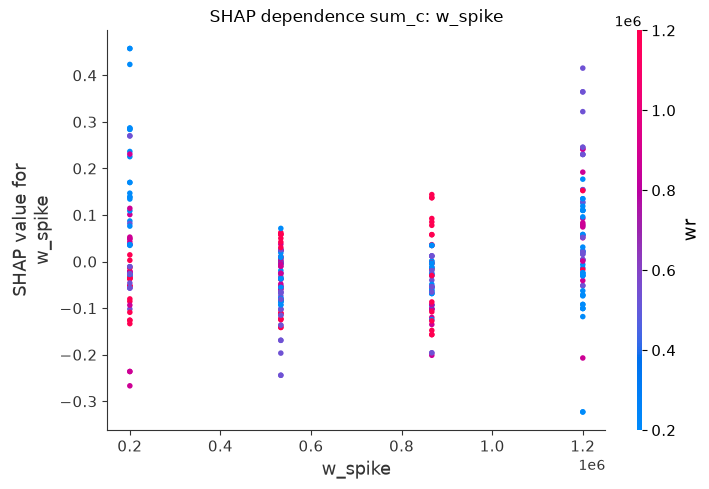

<Figure size 700x500 with 0 Axes>

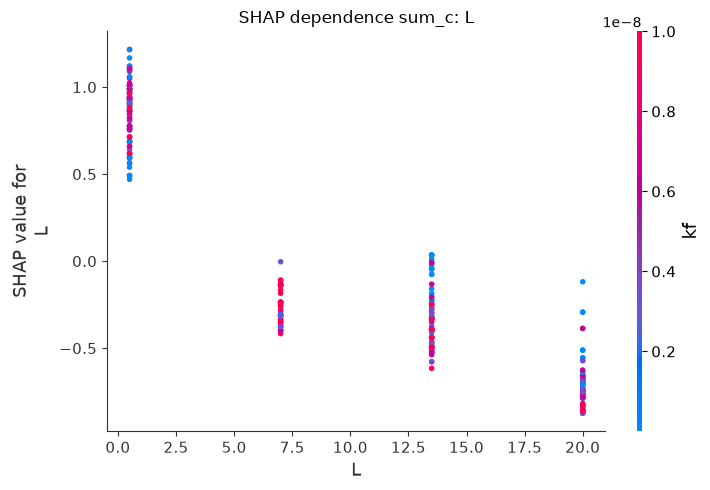

<Figure size 700x500 with 0 Axes>

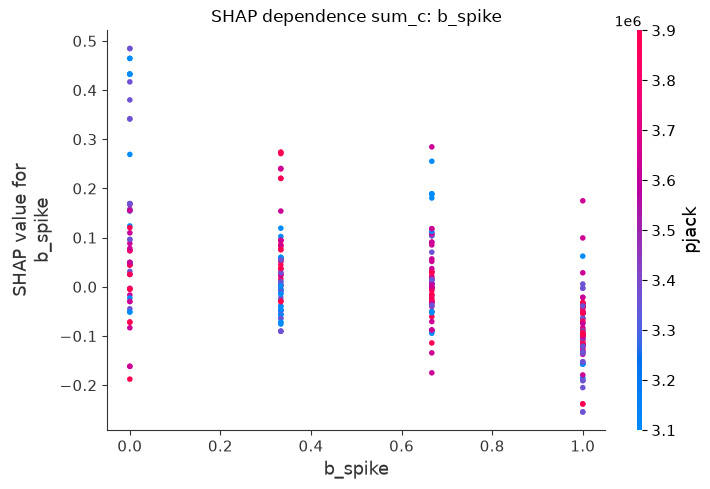

<Figure size 700x500 with 0 Axes>

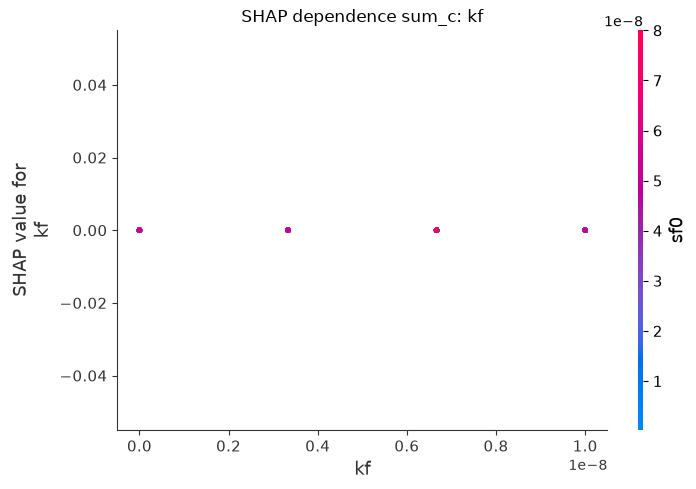

<Figure size 700x500 with 0 Axes>

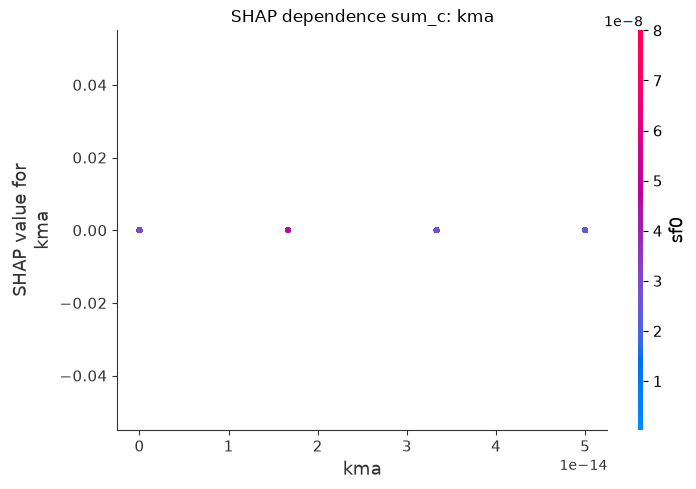

In [15]:
# all nonlinear depdence pairs
for feature in X.columns:
    plt.figure(figsize=(7,5))

    shap.dependence_plot(
        feature,
        final_shap_values.values,
        X,
        display_features=X,
        show=False
    )
    plt.title(f'SHAP dependence {sindex}: {feature}')
    plt.tight_layout()
    plt.show()

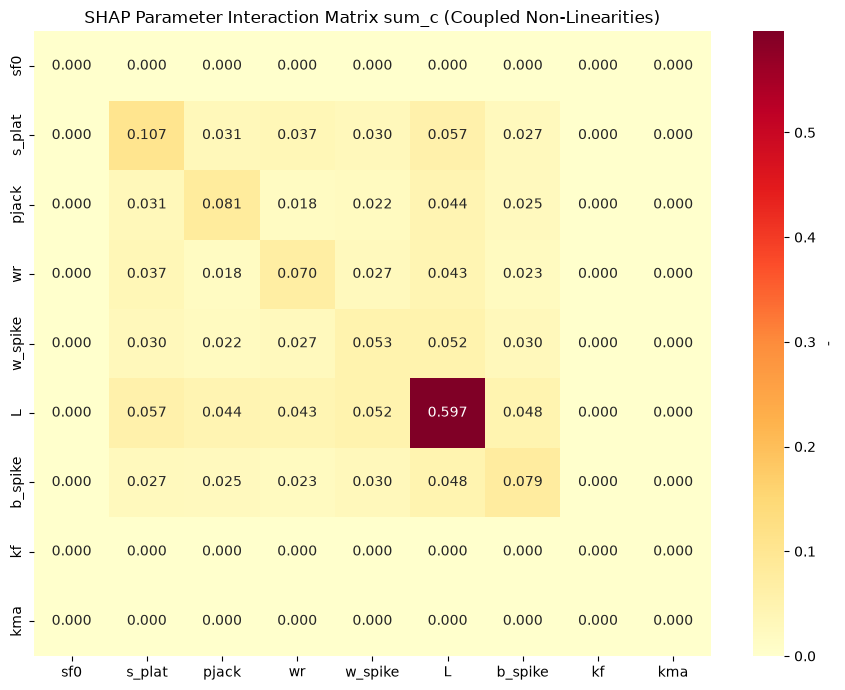

In [ ]:
#couple non-linearities
interation_values= final_explainer.shap_interaction_values(X)
global_interations= np.mean(np.abs(interation_values),axis=0)

fig5, axs=plt.subplots(figsize=(9,7))

sns.heatmap(
    global_interations,
    xticklabels=X.columns,
    yticklabels=X.columns,
    annot=True,
    fmt='.3f',
    cmap='YlOrRd',
    cbar_kws={"label": "-"}
)
plt.title(f"SHAP Parameter Interaction Matrix {sindex} (Coupled Non-Linearities)")
plt.tight_layout()
plt.show()

# fig5.savefig(f'SHAP_SA_BH10_40_6_cnl.pdf',
#               format="pdf",
#             bbox_inches='tight',
#             pad_inches=0.05
#             ) 

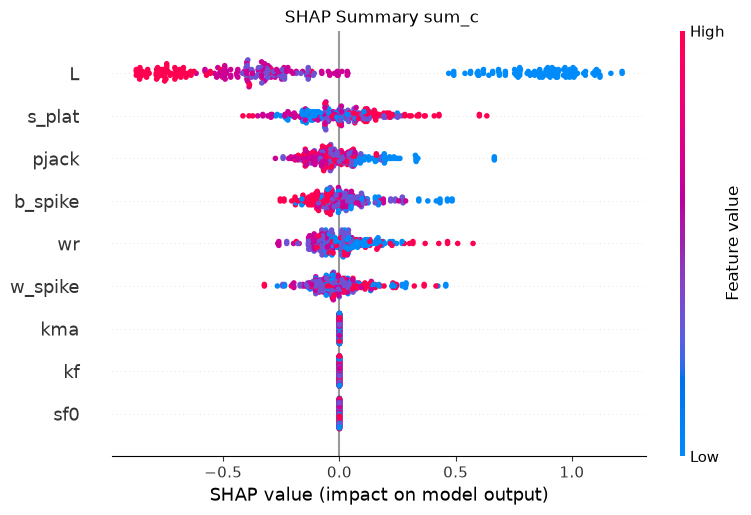

In [ ]:
#summary plot [Pa]
fig6, axs=plt.subplots(figsize=(9,6))
axs=shap.summary_plot(final_shap_values,X,show= False)

plt.title(f' SHAP Summary {sindex}')

# fig6.savefig(f'SHAP_SA_BH10_40_6_shap.pdf',
#               format="pdf",
#             bbox_inches='tight',
#             pad_inches=0.05
#             ) 